In [1]:
import pandas as pd
df=pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [2]:
df.head(5)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

In [7]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [9]:
df.isnull()

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False


In [12]:
# 6.	Convert categorical columns (sex, smoker, region) into numerical format. 
encoded_df = pd.get_dummies(df, columns=['sex','smoker','region'])
encoded_df

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,True,False,False,True,False,False,False,True
1,18,33.770,1,1725.55230,False,True,True,False,False,False,True,False
2,28,33.000,3,4449.46200,False,True,True,False,False,False,True,False
3,33,22.705,0,21984.47061,False,True,True,False,False,True,False,False
4,32,28.880,0,3866.85520,False,True,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,False,True,True,False,False,True,False,False
1334,18,31.920,0,2205.98080,True,False,True,False,True,False,False,False
1335,18,36.850,0,1629.83350,True,False,True,False,False,False,True,False
1336,21,25.800,0,2007.94500,True,False,True,False,False,False,False,True


In [13]:
encoded_df = encoded_df.astype(int)
encoded_df

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27,0,16884,1,0,0,1,0,0,0,1
1,18,33,1,1725,0,1,1,0,0,0,1,0
2,28,33,3,4449,0,1,1,0,0,0,1,0
3,33,22,0,21984,0,1,1,0,0,1,0,0
4,32,28,0,3866,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,30,3,10600,0,1,1,0,0,1,0,0
1334,18,31,0,2205,1,0,1,0,1,0,0,0
1335,18,36,0,1629,1,0,1,0,0,0,1,0
1336,21,25,0,2007,1,0,1,0,0,0,0,1


In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
encoded_df[['age', 'bmi']] = scaler.fit_transform(df[['age', 'bmi']])
encoded_df

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,-1.438764,-0.453320,0,16884,1,0,0,1,0,0,0,1
1,-1.509965,0.509621,1,1725,0,1,1,0,0,0,1,0
2,-0.797954,0.383307,3,4449,0,1,1,0,0,0,1,0
3,-0.441948,-1.305531,0,21984,0,1,1,0,0,1,0,0
4,-0.513149,-0.292556,0,3866,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.768473,0.050297,3,10600,0,1,1,0,0,1,0,0
1334,-1.509965,0.206139,0,2205,1,0,1,0,1,0,0,0
1335,-1.509965,1.014878,0,1629,1,0,1,0,0,0,1,0
1336,-1.296362,-0.797813,0,2007,1,0,1,0,0,0,0,1


In [18]:
from sklearn.model_selection import train_test_split

X = encoded_df.drop(columns=['charges'])
y = encoded_df['charges']

# 10. Split the dataset into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

764      9095
887      5272
890     29330
1293     9301
259     33750
        ...  
109     47055
575     12222
535      6067
543     63770
846      9872
Name: charges, Length: 268, dtype: int32

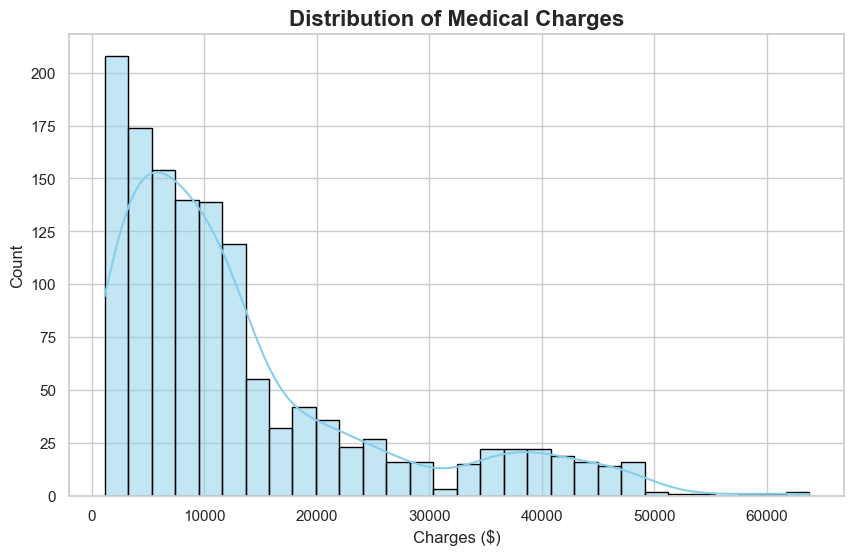

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")


plt.figure(figsize=(10, 6))


sns.histplot(df['charges'], bins=30, kde=True, color='skyblue', edgecolor='black')


plt.title('Distribution of Medical Charges', fontsize=16, fontweight='bold')
plt.xlabel('Charges ($)', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.show()

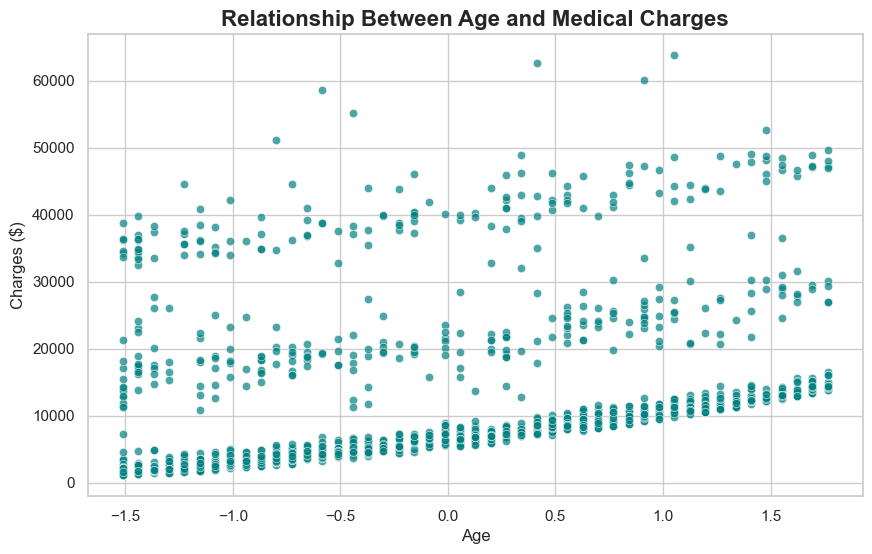

In [23]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='age', y='charges', alpha=0.7, color='teal')


plt.title('Relationship Between Age and Medical Charges', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Charges ($)', fontsize=12)


plt.show()

--- 13. Average Charges: Smokers vs Non-Smokers ---
smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64




<Figure size 1000x600 with 0 Axes>

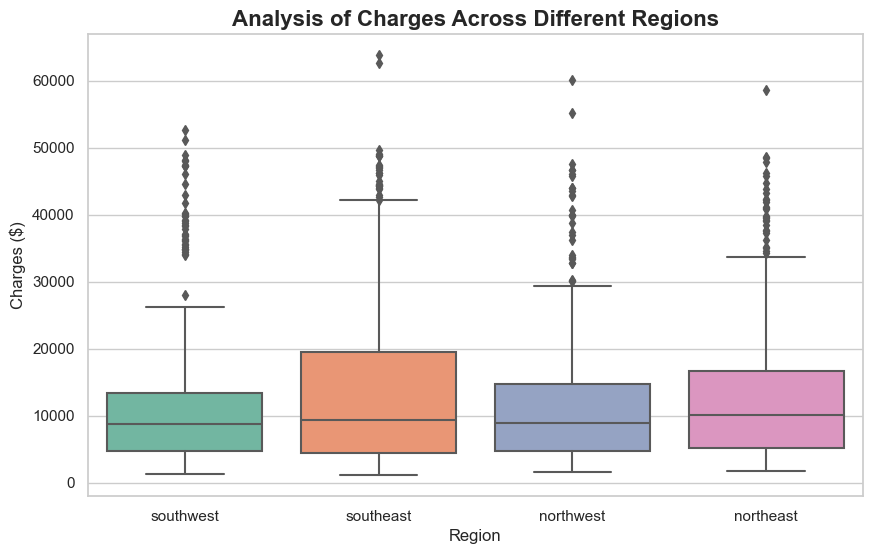

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


avg_charges_smoker = df.groupby('smoker')['charges'].mean()

print("--- 13. Average Charges: Smokers vs Non-Smokers ---")
print(avg_charges_smoker)
print("\n" + "="*50 + "\n")


plt.figure(figsize=(10, 6))





plt.figure(figsize=(10, 6))


sns.boxplot(data=df, x='region', y='charges', palette='Set2')


plt.title('Analysis of Charges Across Different Regions', fontsize=16, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Charges ($)', fontsize=12)

plt.show()


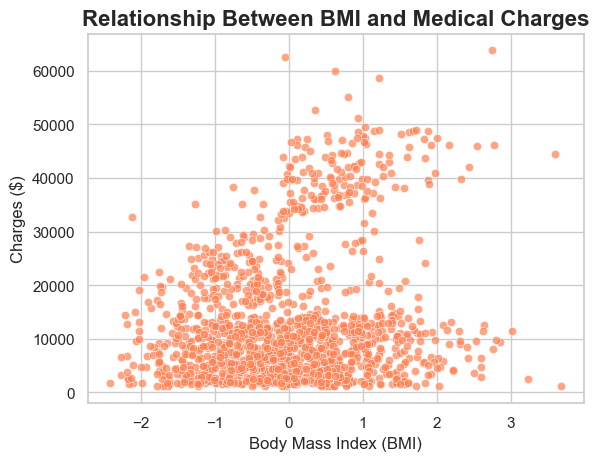

In [25]:
sns.scatterplot(data=df, x='bmi', y='charges', alpha=0.7, color='coral')

plt.title('Relationship Between BMI and Medical Charges', fontsize=16, fontweight='bold')
plt.xlabel('Body Mass Index (BMI)', fontsize=12)
plt.ylabel('Charges ($)', fontsize=12)

plt.show()

In [27]:
#16.	Train a Linear Regression model on the dataset. 
from sklearn.linear_model import LinearRegression


model = LinearRegression()


model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# Optional: Print the model coefficients to see feature importance
print(f"Model Intercept: {model.intercept_}")
print(f"Model Coefficients: {model.coef_}")



Linear Regression model trained successfully!
Model Intercept: 19836.607177072554
Model Coefficients: [ 3.60915711e+03  2.05489948e+03  4.25290848e+02  9.28039088e+00
 -9.28039088e+00 -1.18255543e+04  1.18255543e+04  4.59609491e+02
  8.88956782e+01 -1.98297922e+02 -3.50207247e+02]


In [28]:
# 17. Predict charges using the test data
y_pred = model.predict(X_test)

# Display the first 5 predictions alongside the actual values for comparison
predictions_compare = pd.DataFrame({'Actual Charges': y_test, 'Predicted Charges': y_pred})
print(predictions_compare.head())


      Actual Charges  Predicted Charges
764             9095        8969.070841
887             5272        7068.213663
890            29330       36857.865612
1293            9301        9454.207479
259            33750       26972.645036


In [30]:
from sklearn.tree import DecisionTreeRegressor

# 18. Initialize the Decision Tree Regressor
# random_state ensures reproducibility; max_depth prevents the tree from overfitting
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)

# Train (fit) the model on the training data
tree_model.fit(X_train, y_train)

print("Decision Tree Regressor trained successfully!")
tree_model

Decision Tree Regressor trained successfully!


DecisionTreeRegressor(max_depth=5, random_state=42)

In [32]:
from sklearn.ensemble import RandomForestRegressor

# 19. Initialize the Random Forest Regressor

rf_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

# Train (fit) the model on the training data
rf_model.fit(X_train, y_train)

print("Random Forest Regressor trained successfully!")
rf_model

Random Forest Regressor trained successfully!


RandomForestRegressor(max_depth=5, random_state=42)

In [33]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Generate predictions for the test dataset from all three models
y_pred_lr = model.predict(X_test)         # Linear Regression
y_pred_dt = tree_model.predict(X_test)    # Decision Tree
y_pred_rf = rf_model.predict(X_test)      # Random Forest

# 2. Create a dictionary to hold the calculated evaluation metrics
metrics_summary = {
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'R² Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_rf)
    ],
    'MAE ($)': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_dt),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    'RMSE ($)': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_dt)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ]
}

# 3. Convert to a DataFrame for clean, tabular display
comparison_df = pd.DataFrame(metrics_summary)
print("--- Model Performance Comparison ---")
print(comparison_df.to_string(index=False))

# 4. Optional: Display actual vs predicted values for the first 5 rows
print("\n--- Sample Predictions Comparison ---")
sample_comparison = pd.DataFrame({
    'Actual Charges': y_test,
    'LR Predicted': y_pred_lr,
    'DT Predicted': y_pred_dt,
    'RF Predicted': y_pred_rf
})
print(sample_comparison.head())


--- Model Performance Comparison ---
            Model  R² Score     MAE ($)    RMSE ($)
Linear Regression  0.783594 4181.201357 5796.269921
    Decision Tree  0.843503 2850.000071 4929.083955
    Random Forest  0.872895 2549.567415 4442.169884

--- Sample Predictions Comparison ---
      Actual Charges  LR Predicted  DT Predicted  RF Predicted
764             9095   8969.070841  10550.201439  10118.364194
887             5272   7068.213663   5242.567568   5851.790689
890            29330  36857.865612  26870.588235  27164.096443
1293            9301   9454.207479  10550.201439   9984.806217
259            33750  26972.645036  34232.307692  34971.515913


In [34]:
# 21.	Calculate Mean Absolute Error (MAE) for Linear Regression. 
from sklearn.metrics import mean_absolute_error

# 21. Calculate Mean Absolute Error (MAE) for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression Mean Absolute Error (MAE): ${mae_lr:,.2f}")


Linear Regression Mean Absolute Error (MAE): $4,181.20


In [35]:
from sklearn.metrics import mean_squared_error
import numpy as np

# 22. Calculate Mean Squared Error (MSE)
mse_lr = mean_squared_error(y_test, y_pred_lr)
print(f"Linear Regression Mean Squared Error (MSE): {mse_lr:,.2f}")

# 23. Calculate Root Mean Squared Error (RMSE)
rmse_lr = np.sqrt(mse_lr)
print(f"Linear Regression Root Mean Squared Error (RMSE): ${rmse_lr:,.2f}")


Linear Regression Mean Squared Error (MSE): 33,596,745.00
Linear Regression Root Mean Squared Error (RMSE): $5,796.27


In [36]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# =====================================================================
# 24. Compute R² score for Linear Regression model performance
# =====================================================================
r2_lr = r2_score(y_test, y_pred_lr)
print(f"Linear Regression R² Score: {r2_lr:.4f}")
print("\n" + "="*50 + "\n")


# =====================================================================
# 25. Compare all models based on evaluation metrics
# =====================================================================
# Define a helper function to quickly generate all metrics for a model
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return [r2, mae, rmse]

# Compile the metrics into a structured summary table
comparison_data = {
    'Metric': ['R² Score (Higher is Better)', 'MAE (Lower is Better)', 'RMSE (Lower is Better)'],
    'Linear Regression': calculate_metrics(y_test, y_pred_lr),
    'Decision Tree': calculate_metrics(y_test, y_pred_dt),
    'Random Forest': calculate_metrics(y_test, y_pred_rf)
}

# Convert to DataFrame and format for clear reading
metrics_df = pd.DataFrame(comparison_data)

print("--- 25. Overall Model Evaluation Summary ---")
print(metrics_df.to_string(index=False))


Linear Regression R² Score: 0.7836


--- 25. Overall Model Evaluation Summary ---
                     Metric  Linear Regression  Decision Tree  Random Forest
R² Score (Higher is Better)           0.783594       0.843503       0.872895
      MAE (Lower is Better)        4181.201357    2850.000071    2549.567415
     RMSE (Lower is Better)        5796.269921    4929.083955    4442.169884


--- 26. Random Forest Feature Importances ---
         Feature  Importance
      smoker_yes    0.395049
       smoker_no    0.285065
             bmi    0.185426
             age    0.120048
        children    0.009879
region_northeast    0.001847
region_northwest    0.001090
region_southwest    0.000631
region_southeast    0.000518
      sex_female    0.000244
        sex_male    0.000203




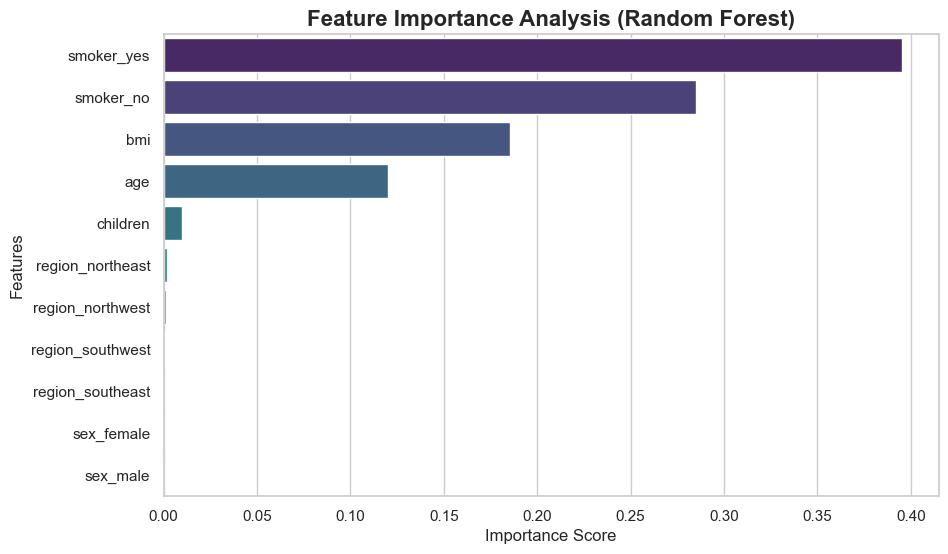

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# =====================================================================
# 26. Feature Importance Analysis using Random Forest
# =====================================================================
# Extract feature importance weights from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame to sort and organize the importances
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("--- 26. Random Forest Feature Importances ---")
print(importance_df.to_string(index=False))
print("\n" + "="*50 + "\n")

# Plot the Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance Analysis (Random Forest)', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.show()




In [40]:
# =====================================================================
# 27. Apply Cross-Validation (5-Fold CV)
# =====================================================================
# Perform 5-fold cross-validation on the full dataset (X and y) using the Random Forest model
# We use scoring='r2' to evaluate performance via the R² score
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')

print("--- 27. 5-Fold Cross-Validation Results (R² Scores) ---")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: R² = {score:.4f}")

print(f"\nMean R² Score: {np.mean(cv_scores):.4f}")
print(f"Standard Deviation of R² Scores: {np.std(cv_scores):.4f}")

--- 27. 5-Fold Cross-Validation Results (R² Scores) ---
Fold 1: R² = 0.8816
Fold 2: R² = 0.8007
Fold 3: R² = 0.8922
Fold 4: R² = 0.8426
Fold 5: R² = 0.8705

Mean R² Score: 0.8575
Standard Deviation of R² Scores: 0.0329


SyntaxError: expression expected after dictionary key and ':' (2778615847.py, line 10)